In [62]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron    # Used for simple linear classification tasks.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential     # Sequential lets you build a neural network layer-by-layer in Keras.

from tensorflow.keras.layers import Dense     #Dense makes the final predictions
from tensorflow.keras.layers import Conv2D     # Conv2D extracts features
from tensorflow.keras.layers import Flatten    # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D     # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout          # Dropout prevents overfitting

from tensorflow.keras.utils import to_categorical     # converts numeric class labels into one-hot encoded format for training classification models


In [63]:
df=pd.read_csv("train.csv")
df_test=pd.read_csv("test.csv")

In [64]:
df

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41996,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41997,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41998,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [65]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [66]:
df.isnull().sum()

,0
label,0
pixel0,0
pixel1,0
pixel2,0
pixel3,0
...,...
pixel779,0
pixel780,0
pixel781,0
pixel782,0


In [67]:
df.dropna(axis=0)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41996,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41997,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41998,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [68]:
X=df.drop('label',axis=1).values
y=df['label'].values
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [69]:
X_train=X_train.astype(float)/255.0
X_test=X_test.astype(float)/255.0

In [70]:
X_train_img = X_train.reshape(-1, 28, 28)
X_test_img = X_test.reshape(-1, 28, 28)

In [84]:
y_train_cat=to_categorical(y_train,num_classes=10)
y_test_cat=to_categorical(y_test,num_classes=10)

In [72]:
perceptron=Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10,activation='softmax')
])

In [73]:
perceptron.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [74]:
history=perceptron.fit(X_train_img,y_train_cat,epochs=10,validation_split=0.2,verbose=1)
#

Epoch 1/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8419 - loss: 0.6154 - val_accuracy: 0.8979 - val_loss: 0.3863
Epoch 2/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9047 - loss: 0.3416 - val_accuracy: 0.9107 - val_loss: 0.3289
Epoch 3/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9134 - loss: 0.3044 - val_accuracy: 0.9144 - val_loss: 0.3130
Epoch 4/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9194 - loss: 0.2854 - val_accuracy: 0.9193 - val_loss: 0.2963
Epoch 5/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9228 - loss: 0.2738 - val_accuracy: 0.9201 - val_loss: 0.2931
Epoch 6/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9250 - loss: 0.2652 - val_accuracy: 0.9211 - val_loss: 0.2896
Epoch 7/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9271 - loss: 0.2588 - val_accuracy: 0.9220 - val_loss: 0.2853
Epoch 8/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9286 - loss: 0.2532 - val_accuracy: 0.

ANN

In [75]:
ann=Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128,activation='relu'),
    Dense(64,activation='relu'),
    Dense(32,activation='relu'),
    Dense(10,activation='softmax')
])

In [76]:
ann.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [77]:
history=ann.fit(X_train_img,y_train_cat,epochs=10,validation_split=0.2,verbose=1,batch_size=32)
#

Epoch 1/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9012 - loss: 0.3386 - val_accuracy: 0.9455 - val_loss: 0.1901
Epoch 2/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9571 - loss: 0.1375 - val_accuracy: 0.9585 - val_loss: 0.1430
Epoch 3/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9709 - loss: 0.0966 - val_accuracy: 0.9619 - val_loss: 0.1324
Epoch 4/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.9778 - loss: 0.0717 - val_accuracy: 0.9680 - val_loss: 0.1117
Epoch 5/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9822 - loss: 0.0544 - val_accuracy: 0.9676 - val_loss: 0.1194
Epoch 6/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9846 - loss: 0.0463 - val_accuracy: 0.9618 - val_loss: 0.1439
Epoch 7/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9888 - loss: 0.0342 - val_accuracy: 0.9695 - val_loss: 0.1251
Epoch 8/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9900 - loss: 0.0286 - val_accuracy: 

In [78]:
X_train_cnn=X_train.reshape(-1,28,28,1)
X_test_cnn=X_test.reshape(-1,28,28,1)

In [79]:
cnn=Sequential([
    Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)),#32 filter ka size hai or kernal size filter ke matrix ka size hai
    MaxPooling2D((2,2)),
    Conv2D(64,(3,3),activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),#sb kr liye conv,pooling phit hmko usko 1d arr me cnvert krke ANN me dal denge
    Dense(128,activation='relu'),
    Dropout(0.5),#128 neuron me se 50% deactivate ho jaegga sirf ek baar liye or jitni baarr forward ,backward hoga usme sirf ek neuron pe focus nhi hoga jisse hmra model overfit nhi hoga
    Dense(10,activation='softmax')
])

In [80]:
cnn.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [ ]:
history_cnn=cnn.fit(X_train_cnn,y_train_cat,epochs=10,validation_split=0.2,verbose=1,batch_size=32)
#

Epoch 1/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 32s 36ms/step - accuracy: 0.9032 - loss: 0.3102 - val_accuracy: 0.9760 - val_loss: 0.0824
Epoch 2/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 41s 35ms/step - accuracy: 0.9681 - loss: 0.1070 - val_accuracy: 0.9780 - val_loss: 0.0723
Epoch 3/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 30s 36ms/step - accuracy: 0.9754 - loss: 0.0800 - val_accuracy: 0.9796 - val_loss: 0.0716
Epoch 4/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 30s 36ms/step - accuracy: 0.9807 - loss: 0.0632 - val_accuracy: 0.9876 - val_loss: 0.0483
Epoch 5/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 32s 37ms/step - accuracy: 0.9839 - loss: 0.0532 - val_accuracy: 0.9856 - val_loss: 0.0501
Epoch 6/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 41s 37ms/step - accuracy: 0.9850 - loss: 0.0434 - val_accuracy: 0.9859 - val_loss: 0.0510
Epoch 7/10
840/840 ━━━━━━━━━━━━━━━━━━━━ 28s 33ms/step - accuracy: 0.9882 - loss: 0.0375 - val_accuracy: 0.9863 - val_loss: 0.0461
Epoch 8/10


In [85]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


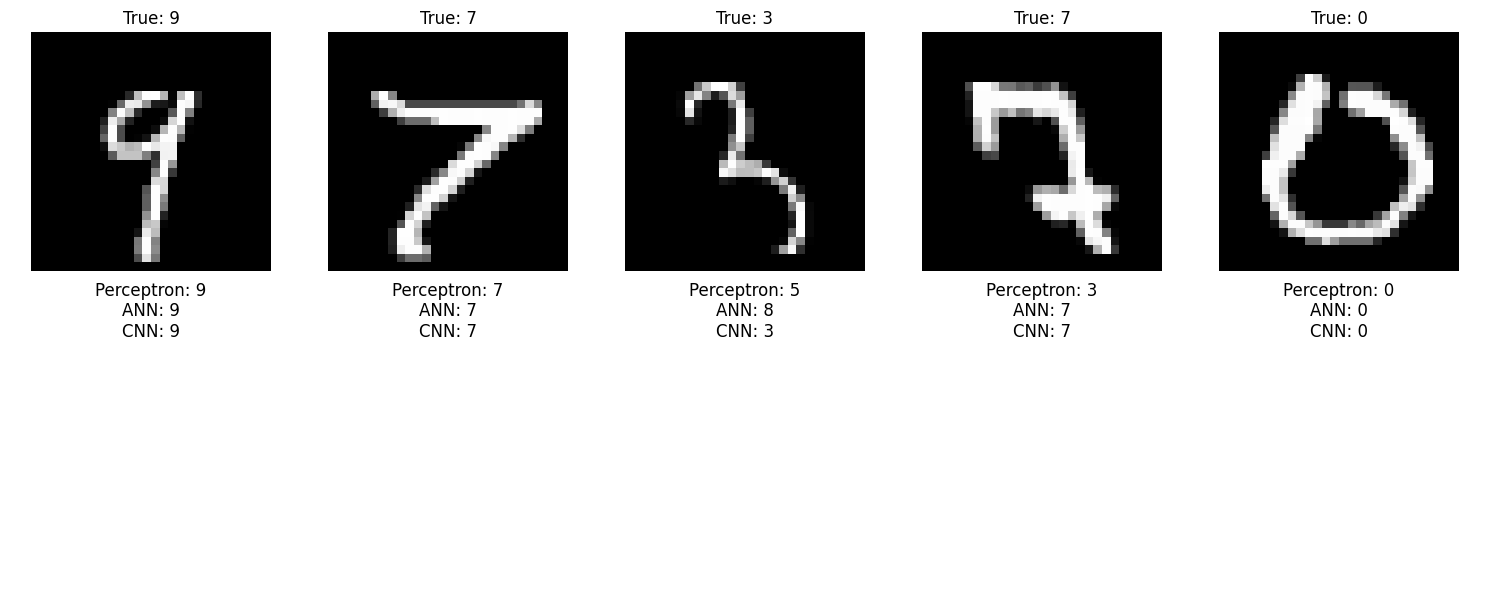

In [90]:
show_side_by_side([perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], X_test_img, X_test_cnn, y_test, 5)
